#30DayMapChallenge – Day 8: Utopia

Austria from Scratch – What if we could redesign an entire country?

For Day 8 of the #30DayMapChallenge, I explored a rather radical idea: What if we could completely rethink Austria's settlement structure, without being constrained by existing cities, roads, railways, or administrative boundaries? Using Python, GeoPandas, and spatial optimization, I developed a hypothetical model that redistributes Austria's entire population of approximately 9.2 million people into just nine newly planned urban regions. The model considers natural geographical conditions, particularly elevation and terrain slope, while limiting population density to 12,000 inhabitants per square kilometer. The objective is to create a compact, polycentric settlement pattern that makes efficient use of space and minimizes infrastructure requirements.

The resulting map shows nine hypothetical urban regions connected by a simplified infrastructure network based on a Minimum Spanning Tree. The settlement areas appear as small, concentrated clusters within Austria's otherwise largely unoccupied landscape. Of course, this is not a realistic planning proposal. It deliberately ignores historical development, cultural identities, existing communities, and many other factors that shape where people live. But that is precisely what makes the experiment interesting to me. As someone working with spatial data and regional development, I find it fascinating to question the geographical patterns we usually take for granted. Utopia, in this case, is not necessarily about designing a perfect country, but about using spatial analysis to explore what a completely different one might look like.

#30DayMapChallenge #Day8 #Utopia #Austria #SpatialOptimization #GIS #Python #GeoPandas #UrbanPlanning #RegionalDevelopment

In [31]:
import geopandas as gpd
import numpy as np
import pandas as pd


candidates = gpd.read_file("data/at_dem.gpkg")
candidates["area_km2"] = pd.to_numeric(candidates["area_km2"], errors="coerce")
# Eignung nach Hangneigung
candidates["score_slope"] = np.interp(
    candidates["slope"],
    [0, 5, 10, 15, 20],
    [1, 1, 0.8, 0.5, 0]
)

# Höhenlage
candidates["score_elevation"] = np.exp(
    -candidates["elevation"].clip(lower=0) / 1500
)

# Gesamteignung
candidates["suitability"] = (
    0.75 * candidates["score_slope"] +
    0.25 * candidates["score_elevation"]
)

# Steile Flächen ausschließen
candidates.loc[
    candidates["slope"] > 20,
    "suitability"
] = 0

# Bevölkerungskapazität
D_MAX = 5000

capacity_raw = (
    candidates["area_km2"] *
    D_MAX *
    candidates["suitability"]
)

capacity_raw = capacity_raw.replace([np.inf, -np.inf], np.nan).fillna(0)

candidates["capacity"] = capacity_raw.round().astype(int)

candidates = candidates[candidates["capacity"] > 0].copy()

In [32]:
import heapq

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree

# --------------------------------------------------
# 1. Parameter
# --------------------------------------------------

N_CITIES = 9
POP_TOTAL = 9_200_000
MAX_DENSITY = 12_000  # Einwohner je km²

MAX_SLOPE = 20        # Grad
MAX_ELEVATION = 1500  # Meter

# Rasterzellen ca. 1 km, inkl. diagonaler Nachbarn
NEIGHBOR_DISTANCE = 1450

# --------------------------------------------------
# 2. Kandidaten vorbereiten
# --------------------------------------------------

gdf = candidates.to_crs(31287).copy()

gdf = gdf[
    gdf.geometry.notna()
    & ~gdf.geometry.is_empty
    & gdf["slope"].notna()
    & gdf["elevation"].notna()
].copy()

gdf["area_km2"] = gdf.geometry.area / 1e6

# Ausschließlich natürliche Standortbedingungen
gdf = gdf[
    (gdf["slope"] <= MAX_SLOPE)
    & (gdf["elevation"] <= MAX_ELEVATION)
    & (gdf["area_km2"] > 0)
].reset_index(drop=True)

# Standortqualität (0 bis 1)
gdf["suitability"] = (
    1
    - 0.7 * gdf["slope"] / MAX_SLOPE
    - 0.3 * gdf["elevation"].clip(lower=0)
      / MAX_ELEVATION
).clip(0, 1)

# Kapazität: maximale Dichte, nicht Ziel-Dichte
gdf["capacity"] = np.floor(
    gdf["area_km2"] * MAX_DENSITY
).astype(int)

# Geometrische Mittelpunkte
points = gdf.geometry.representative_point()

coords = np.column_stack([
    points.x.to_numpy(),
    points.y.to_numpy()
])

capacity = gdf["capacity"].to_numpy()
quality = gdf["suitability"].to_numpy()
slope = gdf["slope"].to_numpy()
elevation = gdf["elevation"].to_numpy()

if capacity.sum() < POP_TOTAL:
    raise ValueError(
        "Nicht genügend Siedlungskapazität vorhanden."
    )

# --------------------------------------------------
# 3. 20 Startpunkte auswählen
# --------------------------------------------------

# Ersten Startpunkt nach Qualität wählen
seeds = [int(np.argmax(quality))]

# Weitere Startpunkte möglichst weit entfernt,
# unter Berücksichtigung der Standortqualität
min_dist = np.linalg.norm(
    coords - coords[seeds[0]], axis=1
)

for _ in range(1, N_CITIES):

    score = min_dist * (0.5 + 0.5 * quality)
    score[seeds] = -np.inf

    idx = int(np.argmax(score))
    seeds.append(idx)

    dist = np.linalg.norm(
        coords - coords[idx], axis=1
    )

    min_dist = np.minimum(min_dist, dist)

seeds = np.array(seeds)

# --------------------------------------------------
# 4. Nachbarschaftsstruktur
# --------------------------------------------------

tree = cKDTree(coords)

# Zuordnung der Rasterzellen
owner = np.full(len(gdf), -1, dtype=int)
population = np.zeros(len(gdf), dtype=int)

# Gleich große Stadtregionen
targets = np.full(
    N_CITIES, POP_TOTAL // N_CITIES, dtype=int
)
targets[:POP_TOTAL % N_CITIES] += 1

remaining = targets.copy()

# --------------------------------------------------
# 5. Kostenfunktion
# --------------------------------------------------

def cell_cost(idx, city):
    distance = np.linalg.norm(
        coords[idx] - coords[seeds[city]]
    )

    return (
        0.55 * distance / 30000
        + 0.30 * slope[idx] / MAX_SLOPE
        + 0.15 * max(elevation[idx], 0)
          / MAX_ELEVATION
    )

# --------------------------------------------------
# 6. Region Growing
# --------------------------------------------------

heap = []
queued = set()

def add_candidate(idx, city):
    if owner[idx] != -1:
        return

    key = (int(idx), int(city))

    if key in queued:
        return

    queued.add(key)

    heapq.heappush(
        heap,
        (cell_cost(idx, city), int(idx), int(city))
    )

# Startzellen reservieren, damit keine Stadt
# von einer anderen verdrängt werden kann
for city, idx in enumerate(seeds):
    owner[idx] = city

    assigned = min(capacity[idx], remaining[city])
    population[idx] = assigned
    remaining[city] -= assigned

# Wachstumsfronten initialisieren
for city, idx in enumerate(seeds):
    for neighbor in tree.query_ball_point(
        coords[idx], NEIGHBOR_DISTANCE
    ):
        add_candidate(neighbor, city)

# Regionen wachsen lassen
while heap and np.any(remaining > 0):

    cost, idx, city = heapq.heappop(heap)

    if owner[idx] != -1:
        continue

    if remaining[city] <= 0:
        continue

    # Zelle der Stadtregion zuweisen
    owner[idx] = city

    assigned = min(
        capacity[idx],
        remaining[city]
    )

    population[idx] = assigned
    remaining[city] -= assigned

    # Neue Nachbarn hinzufügen
    if remaining[city] > 0:
        neighbors = tree.query_ball_point(
            coords[idx],
            NEIGHBOR_DISTANCE
        )

        for neighbor in neighbors:
            add_candidate(neighbor, city)

# --------------------------------------------------
# 7. Ergebnisse prüfen
# --------------------------------------------------

if np.any(remaining > 0):
    raise RuntimeError(
        "Nicht alle Stadtregionen konnten ihre "
        "Zielbevölkerung erreichen. "
        f"Fehlende Bevölkerung: {remaining.sum():,}"
    )

gdf["city_id"] = owner
gdf["population_new"] = population

settlement_cells = gdf[
    gdf["population_new"] > 0
].copy()

print("Stadtregionen:",
      settlement_cells["city_id"].nunique())

print("Bevölkerung:",
      settlement_cells["population_new"].sum())

print("Siedlungsfläche:",
      settlement_cells["area_km2"].sum(), "km²")

settlement_cells.to_file(
    "data/austria_candidates.gpkg",
    layer="settlement_candidates",
    driver="GPKG"
)

Stadtregionen: 9
Bevölkerung: 9200000
Siedlungsfläche: 773.6080524121825 km²


In [33]:
cities = settlement_cells.dissolve(
    by="city_id",
    aggfunc={
        "population_new": "sum",
        "area_km2": "sum",
        "suitability": "mean"
    }
).reset_index()

cities["density"] = (
    cities["population_new"] / cities["area_km2"]
)

cities["geometry_center"] = (
    cities.geometry.representative_point()
)

print(cities[[
    "city_id",
    "population_new",
    "area_km2",
    "density"
]])



   city_id  population_new   area_km2       density
0        0         1022223  85.944106  11894.044252
1        1         1022223  85.942151  11894.314802
2        2         1022222  85.961930  11891.566353
3        3         1022222  85.978938  11889.214129
4        4         1022222  85.957917  11892.121547
5        5         1022222  85.943526  11894.112870
6        6         1022222  85.988915  11887.834626
7        7         1022222  85.942140  11894.304639
8        8         1022222  85.948428  11893.434447


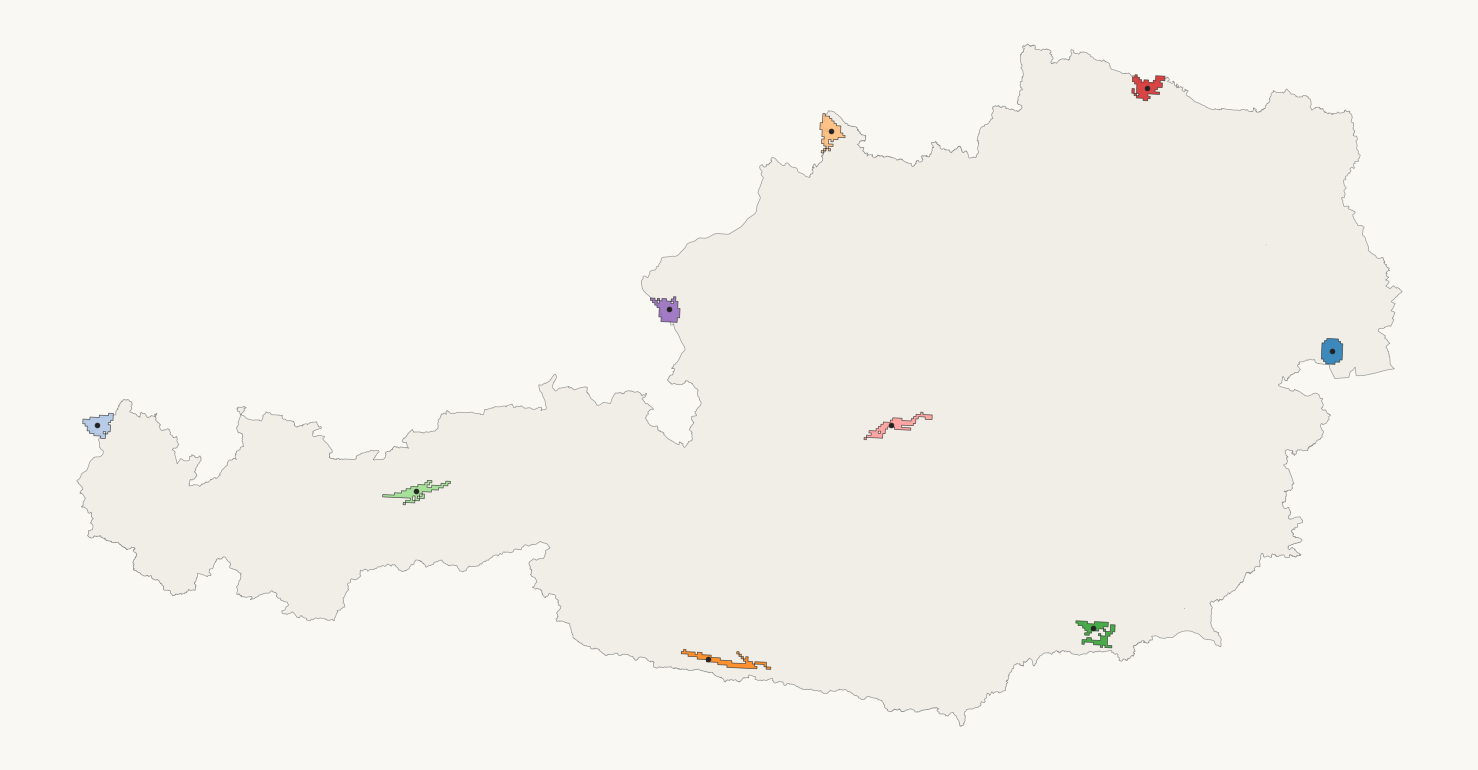

In [34]:
austria = gpd.read_file("data/at_border.geojson")


fig, ax = plt.subplots(figsize=(15, 11))

austria.to_crs(31287).plot(
    ax=ax,
    color="#F0EEE7",
    edgecolor="#999999",
    linewidth=0.5
)

cities.plot(
    ax=ax,
    column="city_id",
    cmap="tab20",
    categorical=True,
    alpha=0.85,
    edgecolor="#333333",
    linewidth=0.5
)

centers = gpd.GeoDataFrame(
    cities[["city_id"]].copy(),
    geometry=gpd.GeoSeries(
        cities["geometry_center"],
        crs=31287
    ),
    crs=31287
)

centers.plot(
    ax=ax,
    color="#222222",
    markersize=12,
    zorder=5
)

ax.set_axis_off()
ax.set_aspect("equal")

fig.patch.set_facecolor("#FAF8F2")

plt.tight_layout()
plt.savefig(
    "maps/08_austria_from_scratch.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Now run:
```
python austria_utopia_optimize.py \
    austria_candidates.gpkg \
    --layer settlement_candidates \
    --iterations 200 \
    --output utopia_9_cities
```